<a href="https://colab.research.google.com/github/icaro-a-santana/applied-computational-intelligence-hm2/blob/main/homework2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# HOMEWORK 02 INTELIGÊNCIA COMPUTACIONAL APLICADA

Modelos de regressão para a solubilidade de compostos químicos (Alternativa 1 do enunciado).

Autores:

Icaro Adriano 609310 (Departamento de Engenharia de Teleinformatica)

Matheus Reis 571954 (Departamento de Engenharia de Teleinformatica)

Alisson Jaime 555083 (Departamento de Engenharia de Teleinformatica)

Vinicius Alexandre Gomes do Nascimento 568594 (Departamento de Engenharia de Teleinformatica)

# CONFIGURAÇÃO DO AMBIENTE

O notebook roda tanto localmente, a partir da raiz do repositório, quanto no Google Colab. No Colab o
diretório de trabalho começa vazio, então a primeira célula clona o repositório do GitHub para ter acesso
ao dataset em `dataset/solubility/`. Localmente nada é baixado.

In [1]:
import os
import subprocess
import sys

REPOSITORIO = 'https://github.com/icaro-a-santana/applied-computational-intelligence-hm2.git'

if 'google.colab' in sys.modules and not os.path.isdir('dataset/solubility'):
    subprocess.run(['git', 'clone', '-q', REPOSITORIO], check=True)
    os.chdir('applied-computational-intelligence-hm2')

print('Diretório de trabalho:', os.getcwd())

Diretório de trabalho: /home/icaro/Desktop/LOCAL/PESSOAL/01_ATIVO/GRADUACAO_2026_2/INTELIGENCIA_COMPUTACIONAL_APLICADA/HOMEWORK_02/applied-computational-intelligence-hm2


Bibliotecas usadas. Os modelos pedidos "do zero" (OLS, ridge, validação cruzada e PLS) usam apenas
numpy; o scikit-learn entra só como referência de comparação e para a rede neural. As matrizes deste
problema são pequenas (951 × 228), e nessa escala o paralelismo do BLAS deixa o treino da rede neural
dezenas de vezes mais lento, por isso limitamos o BLAS a uma thread.

In [2]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import optimize, stats
from threadpoolctl import threadpool_limits

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import GridSearchCV, cross_validate
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PowerTransformer, StandardScaler

threadpool_limits(1)
warnings.filterwarnings('ignore', category=ConvergenceWarning)

SEMENTE = 42      # semente única para todas as partições aleatórias
K = 10            # número de dobras da validação cruzada
DIR_DADOS = os.path.join('dataset', 'solubility')
DIR_FIG = 'figuras'
DIR_TAB = os.path.join('paper', 'tabelas')
os.makedirs(DIR_FIG, exist_ok=True)
os.makedirs(DIR_TAB, exist_ok=True)

plt.rcParams.update({'figure.dpi': 100, 'savefig.dpi': 200, 'savefig.bbox': 'tight',
                     'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})


def salva_figura(fig, nome):
    """Salva a figura em figuras/ para ser incluída no artigo."""
    fig.savefig(os.path.join(DIR_FIG, nome))

# QUESTÃO 0: ANÁLISE EXPLORATÓRIA E PRÉ-PROCESSAMENTO

## Descrição do dataset

O conjunto de dados vem do pacote `AppliedPredictiveModeling` do R e já é fornecido dividido em treino e
teste. Cada linha é um composto químico; as colunas são os preditores e o desfecho é a solubilidade
(log da solubilidade em água). Os arquivos têm o nome da linha na primeira coluna, que o pandas usa como
índice.

In [3]:
def le(nome):
    return pd.read_csv(os.path.join(DIR_DADOS, nome), sep='\t')


X_treino = le('solTrainX.txt')
X_teste = le('solTestX.txt')
y_treino = le('solTrainY.txt')['x'].to_numpy()
y_teste = le('solTestY.txt')['x'].to_numpy()

print('Treino:', X_treino.shape, ' Teste:', X_teste.shape)
print('N total =', len(X_treino) + len(X_teste), ' D =', X_treino.shape[1])
print('Valores ausentes:', X_treino.isna().sum().sum() + X_teste.isna().sum().sum())
print('Colunas iguais entre treino e teste:', list(X_treino.columns) == list(X_teste.columns))
X_treino.iloc[:5, [0, 1, 2, 208, 209, 224, 225, 226, 227]]

Treino: (951, 228)  Teste: (316, 228)
N total = 1267  D = 228
Valores ausentes: 0
Colunas iguais entre treino e teste: True


,FP001,FP002,FP003,MolWeight,NumAtoms,NumRings,HydrophilicFactor,SurfaceArea1,SurfaceArea2
661,0,1,0,208.28,28,3,-0.856,25.78,25.78
662,0,1,0,365.54,49,4,-0.370,52.19,80.43
663,1,1,1,206.31,33,1,-0.330,37.30,37.30
665,0,0,1,136.26,26,1,-0.960,0.00,0.00
668,0,0,1,229.75,31,1,-0.069,53.94,53.94


Os preditores são de três tipos: 208 *fingerprints* binários (`FP001`–`FP208`, presença ou ausência de uma
subestrutura química), 16 contagens (número de átomos, ligações, anéis etc.) e 4 descritores contínuos
(peso molecular, fator hidrofílico e duas áreas superficiais). Separamos os grupos e conferimos que os
*fingerprints* só assumem 0 e 1.

In [4]:
fingerprints = [c for c in X_treino.columns if c.startswith('FP')]
continuas = ['MolWeight', 'HydrophilicFactor', 'SurfaceArea1', 'SurfaceArea2']
contagens = [c for c in X_treino.columns if c not in fingerprints and c not in continuas]
nao_binarias = [c for c in X_treino.columns if c not in fingerprints]   # contagens + contínuas

print('fingerprints:', len(fingerprints), ' contagens:', len(contagens), ' contínuas:', len(continuas))
print('valores distintos nos fingerprints:', np.unique(X_treino[fingerprints].to_numpy()))

freq = X_treino[fingerprints].mean()
print(f'frequência de 1 nos fingerprints: mín {freq.min():.3f}, mediana {freq.median():.3f}, máx {freq.max():.3f}')

duplicadas = X_treino.T.duplicated()
print('colunas exatamente duplicadas no treino:', list(X_treino.columns[duplicadas]))

fingerprints: 208  contagens: 16  contínuas: 4
valores distintos nos fingerprints: [0 1]
frequência de 1 nos fingerprints: mín 0.038, mediana 0.131, máx 0.860
colunas exatamente duplicadas no treino: []


Desfecho: a solubilidade. Comparamos a distribuição em treino e em teste para confirmar que a divisão
fornecida é representativa.

        treino    teste
count  951.000  316.000
mean    -2.719   -2.797
std      2.047    2.078
min    -11.620  -10.410
25%     -3.955   -3.952
50%     -2.510   -2.480
75%     -1.360   -1.372
max      1.580    1.070


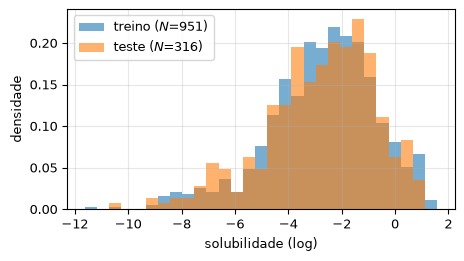

In [5]:
resumo_y = pd.DataFrame({'treino': pd.Series(y_treino).describe(), 'teste': pd.Series(y_teste).describe()})
print(resumo_y.round(3))

fig, ax = plt.subplots(figsize=(5, 2.6))
bins = np.linspace(min(y_treino.min(), y_teste.min()), max(y_treino.max(), y_teste.max()), 30)
ax.hist(y_treino, bins=bins, density=True, alpha=0.6, label=f'treino ($N$={len(y_treino)})')
ax.hist(y_teste, bins=bins, density=True, alpha=0.6, label=f'teste ($N$={len(y_teste)})')
ax.set_xlabel('solubilidade (log)')
ax.set_ylabel('densidade')
ax.legend()
plt.show()

## Assimetria dos preditores

A assimetria amostral de cada preditor é calculada do zero:

$$\gamma_d = \frac{1}{N}\sum_{n=1}^{N}\left(\frac{x_{n,d}-\mu_d}{\sigma_d}\right)^3$$

Os 20 preditores não binários têm assimetria positiva forte: contagens e áreas têm cauda longa à direita.

In [6]:
def assimetria(x):
    x = np.asarray(x, dtype=float)
    z = (x - x.mean()) / x.std()
    return np.mean(z ** 3)


assim_antes = pd.Series({c: assimetria(X_treino[c]) for c in nao_binarias})
print('Assimetria dos 20 preditores não binários (treino):')
print(assim_antes.sort_values(ascending=False).round(2).to_string())
print('\nconferência com scipy:', np.allclose(assim_antes, stats.skew(X_treino[nao_binarias])))

Assimetria dos 20 preditores não binários (treino):
NumSulfer            3.84
HydrophilicFactor    3.40
NumChlorine          3.18
NumHalogen           2.69
NumOxygen            1.77
SurfaceArea1         1.71
NumRotBonds          1.58
NumNitrogen          1.55
SurfaceArea2         1.48
NumAtoms             1.36
NumBonds             1.36
NumDblBonds          1.36
NumHydrogen          1.26
NumRings             1.03
NumNonHAtoms         0.99
MolWeight            0.99
NumNonHBonds         0.97
NumCarbon            0.93
NumAromaticBonds     0.80
NumMultBonds         0.67

conferência com scipy: True


## Transformação de Yeo-Johnson

Para remover a assimetria usamos a transformação de Yeo-Johnson, uma generalização da Box-Cox que aceita
zeros (muitas contagens valem 0) e valores negativos (`HydrophilicFactor`):

$$
\psi(x,\lambda)=\begin{cases}
\left[(x+1)^{\lambda}-1\right]/\lambda, & x\ge 0,\ \lambda\ne 0\\
\ln(x+1), & x\ge 0,\ \lambda=0\\
-\left[(1-x)^{2-\lambda}-1\right]/(2-\lambda), & x<0,\ \lambda\ne 2\\
-\ln(1-x), & x<0,\ \lambda=2
\end{cases}
$$

O parâmetro $\lambda$ de cada preditor é estimado por máxima verossimilhança supondo que o resultado seja
gaussiano. Implementamos a transformação e a log-verossimilhança do zero; a otimização escalar usa
`scipy.optimize`, numa faixa larga, $\lambda \in [-20, 20]$, porque as contagens dominadas por zeros têm ótimo
bem negativo (`NumSulfer` fica perto de $-10$). Nos extremos dessa faixa a transformação pode colapsar todos
os valores num só, em ponto flutuante; a log-verossimilhança trata esse caso como $-\infty$, o mesmo cuidado
que o scikit-learn toma. Os *fingerprints* binários não são transformados: uma variável com dois valores não tem
como ficar simétrica por uma transformação monotônica.

Depois da transformação, **todos** os preditores são padronizados (média 0, desvio 1). Isso é necessário
para a regressão ridge (a penalidade depende da escala) e para o PLS e a rede neural.

Todos os parâmetros (os $\lambda$, as médias e os desvios) são estimados **somente no conjunto de treino**
e reaplicados, sem alteração, no teste. Dentro da validação cruzada o pré-processamento é reajustado em
cada dobra, usando só a parte de treino da dobra.

In [7]:
def yeo_johnson(x, lam):
    x = np.asarray(x, dtype=float)
    saida = np.empty_like(x)
    pos = x >= 0
    if abs(lam) > 1e-10:
        saida[pos] = ((x[pos] + 1) ** lam - 1) / lam
    else:
        saida[pos] = np.log1p(x[pos])
    if abs(lam - 2) > 1e-10:
        saida[~pos] = -((1 - x[~pos]) ** (2 - lam) - 1) / (2 - lam)
    else:
        saida[~pos] = -np.log1p(-x[~pos])
    return saida


def log_verossimilhanca_yj(x, lam):
    """Log-verossimilhança perfilada (Yeo & Johnson, 2000), a menos de constantes."""
    var = yeo_johnson(x, lam).var()
    if var < np.finfo(float).tiny:
        # lambda extremo: em ponto flutuante todos os valores transformados ficam iguais;
        # sem esta proteção, log(0) = -inf viraria verossimilhança +inf e o otimizador escolheria esse lambda
        return -np.inf
    return -len(x) / 2 * np.log(var) + (lam - 1) * np.sum(np.sign(x) * np.log1p(np.abs(x)))


def estima_lambda_yj(x):
    res = optimize.minimize_scalar(lambda lam: -log_verossimilhanca_yj(x, lam),
                                   bounds=(-20, 20), method='bounded', options={'xatol': 1e-8})
    return res.x


class PreProcessador:
    """Yeo-Johnson nos preditores não binários e padronização z de todos os preditores.

    fit() estima lambdas, médias e desvios no conjunto recebido; transform() só os aplica.
    """

    def __init__(self, colunas_yj):
        self.colunas_yj = colunas_yj

    def fit(self, X):
        self.idx_yj_ = [X.columns.get_loc(c) for c in self.colunas_yj]
        A = X.to_numpy(dtype=float)
        self.lambdas_ = np.array([estima_lambda_yj(A[:, j]) for j in self.idx_yj_])
        Z = self._aplica_yj(A)
        self.media_ = Z.mean(axis=0)
        self.desvio_ = Z.std(axis=0)
        self.desvio_[self.desvio_ == 0] = 1.0   # coluna constante numa dobra: só centraliza
        return self

    def _aplica_yj(self, A):
        Z = A.copy()
        for j, lam in zip(self.idx_yj_, self.lambdas_):
            Z[:, j] = yeo_johnson(A[:, j], lam)
        return Z

    def transform(self, X):
        return (self._aplica_yj(X.to_numpy(dtype=float)) - self.media_) / self.desvio_


pre = PreProcessador(nao_binarias).fit(X_treino)
Z_treino = pre.transform(X_treino)
Z_teste = pre.transform(X_teste)        # mesmos parâmetros do treino

# comparação com a implementação pronta do scikit-learn
pt = PowerTransformer(method='yeo-johnson', standardize=False).fit(X_treino[nao_binarias])
print('maior diferença entre os lambdas (nosso vs sklearn):',
      f'{np.max(np.abs(pre.lambdas_ - pt.lambdas_)):.2e}')

maior diferença entre os lambdas (nosso vs sklearn): 3.47e-07


Assimetria antes e depois da transformação, calculada no treino e no teste (no teste, com os parâmetros do
treino).

In [8]:
idx_nb = [X_treino.columns.get_loc(c) for c in nao_binarias]
tabela_assim = pd.DataFrame({
    'lambda': pre.lambdas_,
    'assim. antes': assim_antes.values,
    'assim. depois (treino)': [assimetria(Z_treino[:, j]) for j in idx_nb],
    'assim. depois (teste)': [assimetria(Z_teste[:, j]) for j in idx_nb],
    'fração de zeros': (X_treino[nao_binarias] == 0).mean().values,
}, index=nao_binarias)
print(tabela_assim.round(3).to_string())
print('\n|assimetria| mediana antes: %.2f  depois: %.2f'
      % (tabela_assim['assim. antes'].abs().median(), tabela_assim['assim. depois (treino)'].abs().median()))

                   lambda  assim. antes  assim. depois (treino)  assim. depois (teste)  fração de zeros
MolWeight           0.000         0.988                  -0.000                  0.024            0.000
NumAtoms            0.048         1.364                   0.001                 -0.025            0.000
NumNonHAtoms        0.051         0.993                  -0.004                 -0.044            0.000
NumBonds            0.113         1.360                   0.005                 -0.042            0.000
NumNonHBonds        0.152         0.969                  -0.013                 -0.078            0.000
NumMultBonds        0.358         0.670                  -0.142                 -0.190            0.166
NumRotBonds        -0.078         1.577                   0.021                  0.214            0.286
NumDblBonds        -0.577         1.360                   0.159                  0.341            0.449
NumAromaticBonds    0.133         0.796                  -0.085 

A transformação leva a assimetria das variáveis contínuas e das contagens com muitos valores distintos
para perto de zero. As contagens dominadas por zeros (`NumSulfer`, `NumChlorine`, `NumHalogen`, por exemplo)
continuam assimétricas: com 70% ou mais das observações num único valor, nenhuma transformação monotônica
consegue espalhar essa massa, apenas comprimir a cauda. Os histogramas abaixo mostram quatro preditores
antes e depois.

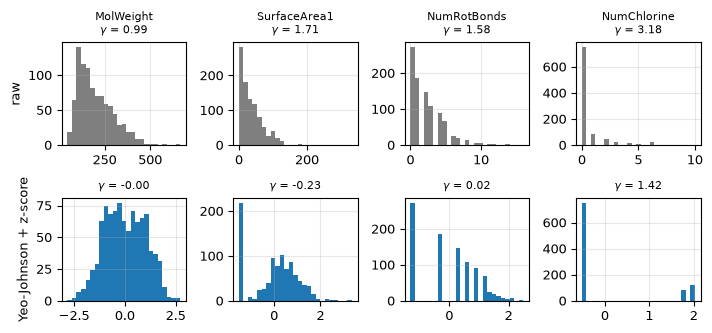

In [9]:
exemplos = ['MolWeight', 'SurfaceArea1', 'NumRotBonds', 'NumChlorine']
fig, eixos = plt.subplots(2, 4, figsize=(7.2, 3.4))
for k, c in enumerate(exemplos):
    j = X_treino.columns.get_loc(c)
    eixos[0, k].hist(X_treino[c], bins=25, color='tab:gray')
    eixos[0, k].set_title(f'{c}\n$\\gamma$ = {assim_antes[c]:.2f}', fontsize=8)
    eixos[1, k].hist(Z_treino[:, j], bins=25, color='tab:blue')
    eixos[1, k].set_title(f'$\\gamma$ = {assimetria(Z_treino[:, j]):.2f}', fontsize=8)
eixos[0, 0].set_ylabel('raw')
eixos[1, 0].set_ylabel('Yeo-Johnson + z-score')
fig.tight_layout()
salva_figura(fig, 'assimetria_antes_depois.png')
plt.show()

## Correlação entre pares de preditores

A matriz de correlação de Pearson é estimada do zero sobre os preditores transformados do treino. Como os
preditores já estão padronizados (média 0 e desvio 1), ela é simplesmente
$\mathbf{R} = \mathbf{Z}^\top\mathbf{Z}/N$.

In [10]:
def matriz_correlacao(A):
    Zc = (A - A.mean(axis=0)) / A.std(axis=0)
    return Zc.T @ Zc / len(A)


R = matriz_correlacao(Z_treino)
print('conferência com np.corrcoef:', np.allclose(R, np.corrcoef(Z_treino, rowvar=False)))

nomes = np.array(X_treino.columns)
i_sup, j_sup = np.triu_indices_from(R, k=1)
r_pares = R[i_sup, j_sup]
print(f'pares de preditores: {len(r_pares)}')
for limiar in (0.5, 0.75, 0.9, 0.99):
    print(f'  |r| > {limiar}: {np.sum(np.abs(r_pares) > limiar)}')
print(f'|r| mediano: {np.median(np.abs(r_pares)):.3f}')

ordem = np.argsort(-np.abs(r_pares))[:15]
print('\nPares mais correlacionados:')
for o in ordem:
    print(f'  {nomes[i_sup[o]]:>18s} x {nomes[j_sup[o]]:<18s} r = {r_pares[o]:+.3f}')

conferência com np.corrcoef: True
pares de preditores: 25878
  |r| > 0.5: 881
  |r| > 0.75: 176
  |r| > 0.9: 47
  |r| > 0.99: 7
|r| mediano: 0.091

Pares mais correlacionados:
               FP134 x NumSulfer          r = +1.000
               FP107 x NumChlorine        r = +0.999
            NumAtoms x NumBonds           r = +0.997
               FP009 x NumHalogen         r = +0.996
               FP058 x FP203              r = +0.995
               FP058 x FP208              r = +0.995
        NumNonHAtoms x NumNonHBonds       r = +0.995
               FP203 x FP208              r = +0.990
               FP032 x FP183              r = +0.985
               FP013 x FP014              r = +0.981
               FP042 x FP194              r = +0.981
               FP063 x NumNitrogen        r = +0.978
               FP032 x FP033              r = +0.969
               FP046 x FP166              r = +0.965
               FP001 x FP163              r = +0.963


Dentro do bloco das 20 variáveis não binárias as correlações são muito altas: número de átomos, de ligações,
de carbonos, peso molecular e área superficial medem, de formas diferentes, o tamanho da molécula. Isso é
colinearidade forte, que torna a matriz $\mathbf{X}^\top\mathbf{X}$ mal condicionada e é exatamente o
cenário em que ridge e PLS devem ajudar em relação ao OLS. Entre *fingerprints* as correlações são em geral
fracas, com alguns pares quase redundantes.

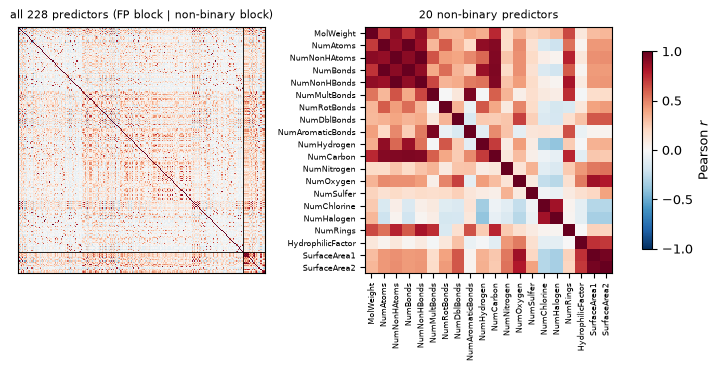

In [11]:
fig, eixos = plt.subplots(1, 2, figsize=(7.2, 3.6), layout='constrained')
im = eixos[0].imshow(R, cmap='RdBu_r', vmin=-1, vmax=1, interpolation='nearest')
eixos[0].axhline(len(fingerprints) - 0.5, color='k', lw=0.6)
eixos[0].axvline(len(fingerprints) - 0.5, color='k', lw=0.6)
eixos[0].set_title('all 228 predictors (FP block | non-binary block)', fontsize=8)
eixos[0].set_xticks([]); eixos[0].set_yticks([]); eixos[0].grid(False)

R_nb = R[np.ix_(idx_nb, idx_nb)]
eixos[1].imshow(R_nb, cmap='RdBu_r', vmin=-1, vmax=1, interpolation='nearest')
eixos[1].set_xticks(range(len(nao_binarias)))
eixos[1].set_xticklabels(nao_binarias, rotation=90, fontsize=6)
eixos[1].set_yticks(range(len(nao_binarias)))
eixos[1].set_yticklabels(nao_binarias, fontsize=6)
eixos[1].set_title('20 non-binary predictors', fontsize=8)
eixos[1].grid(False)
fig.colorbar(im, ax=eixos, shrink=0.8, label='Pearson $r$')
salva_figura(fig, 'matriz_correlacao.png')
plt.show()

Um resumo mais compacto da colinearidade é o número de condição de $\mathbf{Z}^\top\mathbf{Z}$ e o
espectro de autovalores de $\mathbf{R}$: autovalores próximos de zero indicam combinações lineares quase
exatas entre preditores.

In [12]:
autovalores_R = np.linalg.eigvalsh(R)[::-1]
print(f'maior autovalor: {autovalores_R[0]:.2f}   menor: {autovalores_R[-1]:.2e}')
print(f'número de condição de Z^T Z: {autovalores_R[0] / autovalores_R[-1]:.2e}')
print('autovalores < 0.01:', np.sum(autovalores_R < 0.01))
print('componentes para 90% da variância:', np.searchsorted(np.cumsum(autovalores_R) / autovalores_R.sum(), 0.9) + 1)

maior autovalor: 28.31   menor: 2.88e-08
número de condição de Z^T Z: 9.82e+08
autovalores < 0.01: 22
componentes para 90% da variância: 57


## Correlação entre cada preditor e o desfecho

Calculamos a correlação de Pearson (linear) e a de Spearman (monotônica, baseada em postos) entre cada
preditor transformado e a solubilidade. Para os *fingerprints* a correlação de Pearson é a correlação
ponto-bisserial, e a relação é linear por construção: um preditor binário só tem dois valores.

In [13]:
def correlacao(a, b):
    a = (a - a.mean()) / a.std()
    b = (b - b.mean()) / b.std()
    return np.mean(a * b)


r_y = pd.Series([correlacao(Z_treino[:, j], y_treino) for j in range(Z_treino.shape[1])], index=nomes)
rho_y = pd.Series([stats.spearmanr(Z_treino[:, j], y_treino)[0] for j in range(Z_treino.shape[1])], index=nomes)

print('|r| com o desfecho: mediana %.3f, máx %.3f' % (r_y.abs().median(), r_y.abs().max()))
print('preditores com |r| > 0.3:', np.sum(r_y.abs() > 0.3), '  > 0.5:', np.sum(r_y.abs() > 0.5))
print('\nMaiores |r| entre os não binários:')
print(pd.DataFrame({'pearson': r_y[nao_binarias], 'spearman': rho_y[nao_binarias]})
      .reindex(r_y[nao_binarias].abs().sort_values(ascending=False).index).round(3).to_string())
print('\nMaiores |r| entre os fingerprints:')
print(r_y[fingerprints].reindex(r_y[fingerprints].abs().sort_values(ascending=False).index)[:8].round(3).to_string())

|r| com o desfecho: mediana 0.096, máx 0.659
preditores com |r| > 0.3: 39   > 0.5: 6

Maiores |r| entre os não binários:
                   pearson  spearman
MolWeight           -0.659    -0.685
NumCarbon           -0.607    -0.674
NumNonHBonds        -0.585    -0.632
NumNonHAtoms        -0.583    -0.630
NumRings            -0.481    -0.509
NumMultBonds        -0.476    -0.480
NumBonds            -0.459    -0.548
NumAtoms            -0.436    -0.520
NumAromaticBonds    -0.425    -0.458
NumHalogen          -0.387    -0.381
NumChlorine         -0.377    -0.357
HydrophilicFactor    0.365     0.365
SurfaceArea1         0.312     0.193
SurfaceArea2         0.274     0.141
NumOxygen            0.225     0.150
NumNitrogen          0.161     0.101
NumHydrogen         -0.154    -0.256
NumRotBonds         -0.112    -0.150
NumSulfer           -0.073    -0.121
NumDblBonds          0.049    -0.020

Maiores |r| entre os fingerprints:
FP076   -0.538
FP089   -0.501
FP044   -0.477
FP172   -0.432
FP112 

As relações individuais são lineares? Para responder de forma quantitativa, ajustamos para cada preditor não
binário dois modelos univariados: uma reta e um polinômio cúbico. Se a relação fosse linear, o cúbico não
deveria explicar quase nada a mais; um ganho grande em $R^2$ indica curvatura. Os gráficos de dispersão,
com a média do desfecho em faixas do preditor (suavizador por faixas), mostram a forma das relações.

In [14]:
def r2_polinomio(x, y, grau):
    A = np.vander(x, grau + 1)
    coef = np.linalg.lstsq(A, y, rcond=None)[0]
    res = y - A @ coef
    return 1 - res @ res / np.sum((y - y.mean()) ** 2)


lin = pd.DataFrame({
    'R2 linear': [r2_polinomio(Z_treino[:, j], y_treino, 1) for j in idx_nb],
    'R2 cúbico': [r2_polinomio(Z_treino[:, j], y_treino, 3) for j in idx_nb],
}, index=nao_binarias)
lin['ganho'] = lin['R2 cúbico'] - lin['R2 linear']
print(lin.sort_values('ganho', ascending=False).round(3).to_string())

                   R2 linear  R2 cúbico  ganho
NumAromaticBonds       0.181      0.310  0.129
SurfaceArea2           0.075      0.202  0.126
NumHalogen             0.150      0.247  0.097
NumChlorine            0.142      0.238  0.095
NumOxygen              0.051      0.140  0.090
SurfaceArea1           0.097      0.184  0.087
NumMultBonds           0.227      0.295  0.068
NumHydrogen            0.024      0.080  0.056
NumCarbon              0.368      0.415  0.047
NumNonHBonds           0.343      0.383  0.040
NumNonHAtoms           0.340      0.380  0.040
NumRings               0.231      0.269  0.038
NumBonds               0.211      0.244  0.034
NumRotBonds            0.013      0.044  0.031
NumAtoms               0.190      0.213  0.023
NumDblBonds            0.002      0.015  0.013
NumNitrogen            0.026      0.039  0.013
HydrophilicFactor      0.133      0.143  0.010
MolWeight              0.434      0.442  0.008
NumSulfer              0.005      0.011  0.005


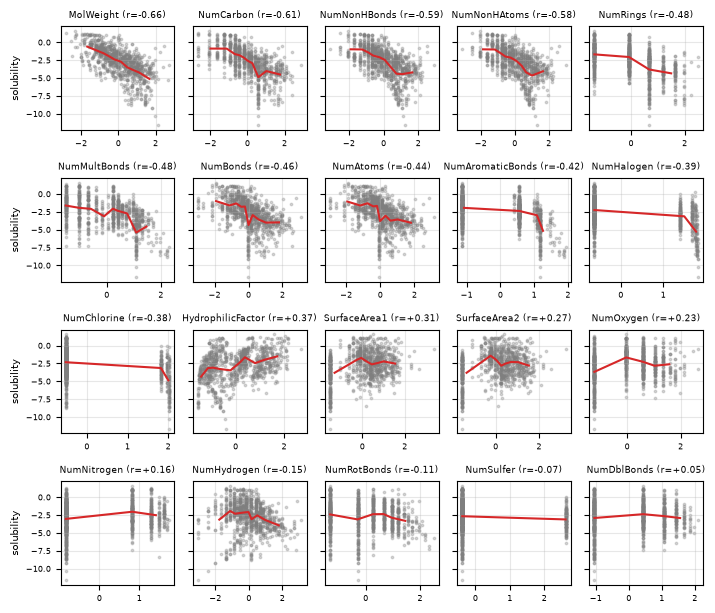

In [15]:
def suavizador_faixas(x, y, n_faixas=10):
    bordas = np.unique(np.quantile(x, np.linspace(0, 1, n_faixas + 1)))
    grupo = np.clip(np.searchsorted(bordas, x, side='right') - 1, 0, len(bordas) - 2)
    cx = [x[grupo == g].mean() for g in np.unique(grupo)]
    cy = [y[grupo == g].mean() for g in np.unique(grupo)]
    return np.array(cx), np.array(cy)


ordem_nb = r_y[nao_binarias].abs().sort_values(ascending=False).index
fig, eixos = plt.subplots(4, 5, figsize=(7.2, 6.2), sharey=True)
for ax, c in zip(eixos.ravel(), ordem_nb):
    j = X_treino.columns.get_loc(c)
    ax.scatter(Z_treino[:, j], y_treino, s=3, alpha=0.3, color='tab:gray')
    cx, cy = suavizador_faixas(Z_treino[:, j], y_treino)
    ax.plot(cx, cy, color='tab:red', lw=1.5)
    ax.set_title(f'{c} (r={r_y[c]:+.2f})', fontsize=6.5)
    ax.tick_params(labelsize=6)
for ax in eixos[:, 0]:
    ax.set_ylabel('solubility', fontsize=7)
fig.tight_layout()
salva_figura(fig, 'preditores_vs_desfecho.png')
plt.show()

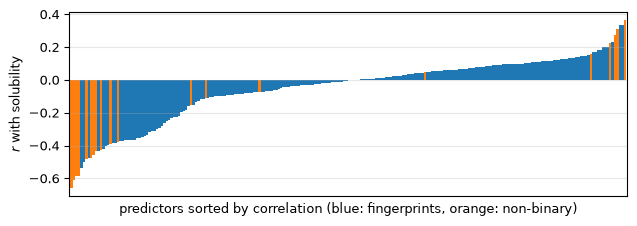

In [16]:
fig, ax = plt.subplots(figsize=(7.2, 2.4))
ordem_r = r_y.sort_values().index
cores = ['tab:orange' if c in nao_binarias else 'tab:blue' for c in ordem_r]
ax.bar(range(len(ordem_r)), r_y[ordem_r], color=cores, width=1.0)
ax.set_xlim(-1, len(ordem_r))
ax.set_xticks([])
ax.set_ylabel('$r$ with solubility')
ax.set_xlabel('predictors sorted by correlation (blue: fingerprints, orange: non-binary)')
salva_figura(fig, 'correlacao_desfecho.png')
plt.show()

**Leitura.** Os preditores mais correlacionados com a solubilidade são os de tamanho molecular (peso
molecular, número de carbonos, átomos e ligações, área superficial), todos com correlação **negativa**:
moléculas maiores são menos solúveis em água. Depois da transformação, a maior parte das relações com o
desfecho é aproximadamente linear (ganho pequeno do cúbico sobre a reta). As exceções com curvatura visível
são justamente algumas contagens com muitos zeros, em que o suavizador muda de inclinação entre o zero e os
valores positivos. Além disso, as relações individuais não dizem nada sobre interações entre preditores,
que só um modelo não linear multivariado consegue capturar; voltamos a isso na Questão 4.

# QUESTÃO 1: REGRESSÃO POR MÍNIMOS QUADRADOS ORDINÁRIOS (OLS)

## Métricas e implementação do zero

Implementamos o RMSE e o $R^2$:

$$\mathrm{RMSE} = \sqrt{\frac{1}{N}\sum_{n}(y_n-\hat y_n)^2}, \qquad
R^2 = 1-\frac{\sum_n (y_n-\hat y_n)^2}{\sum_n (y_n-\bar y)^2}$$

e o OLS pela solução das equações normais com intercepto,
$\hat{\boldsymbol\beta} = (\mathbf{A}^\top\mathbf{A})^{-1}\mathbf{A}^\top\mathbf{y}$, onde
$\mathbf{A} = [\mathbf{1}\ \mathbf{Z}]$. O sistema linear é resolvido com `np.linalg.solve` (não se
inverte a matriz explicitamente). Se $\mathbf{A}$ não tiver posto completo, $\mathbf{A}^\top\mathbf{A}$ é
singular e há infinitas soluções; nesse caso usamos a de norma mínima,
$\hat{\boldsymbol\beta} = \mathbf{A}^{+}\mathbf{y}$, com a pseudo-inversa de Moore-Penrose. É o mesmo
critério do `LinearRegression` do scikit-learn.

In [17]:
def rmse(y, y_pred):
    return np.sqrt(np.mean((y - y_pred) ** 2))


def r2(y, y_pred):
    return 1 - np.sum((y - y_pred) ** 2) / np.sum((y - np.mean(y)) ** 2)


class OLS:
    def fit(self, X, y):
        A = np.column_stack([np.ones(len(X)), X])
        if np.linalg.matrix_rank(A) == A.shape[1]:
            beta = np.linalg.solve(A.T @ A, A.T @ y)
        else:
            # posto incompleto: A^T A é singular e a solução não é única;
            # usamos a de norma mínima, pela pseudo-inversa (via SVD)
            beta = np.linalg.pinv(A) @ y
        self.intercept_, self.coef_ = beta[0], beta[1:]
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_


A_treino = np.column_stack([np.ones(len(Z_treino)), Z_treino])
print('posto de [1 Z]:', np.linalg.matrix_rank(A_treino), 'de', A_treino.shape[1], 'colunas')
print(f'número de condição de A^T A: {np.linalg.cond(A_treino.T @ A_treino):.2e}')

posto de [1 Z]: 229 de 229 colunas
número de condição de A^T A: 9.82e+08


Com o treino completo a matriz de projeto tem posto completo, então as equações normais têm solução única,
apesar do número de condição alto causado pela colinearidade vista na Questão 0. Isso não vale em todas as
dobras da validação cruzada: alguns *fingerprints* raros coincidem exatamente com outro preditor quando parte
dos compostos é retirada (por exemplo, `FP134` e `NumSulfer` têm correlação 1,000 no treino), e é nessas
dobras que o caso da pseudo-inversa é usado. Ajustamos o modelo no treino e avaliamos no
teste; em seguida, comparamos com o `LinearRegression` do scikit-learn ajustado nos mesmos dados.

In [18]:
ols = OLS().fit(Z_treino, y_treino)
pred_ols = ols.predict(Z_teste)

ols_sk = LinearRegression().fit(Z_treino, y_treino)
pred_ols_sk = ols_sk.predict(Z_teste)

print(f'OLS do zero : RMSE teste = {rmse(y_teste, pred_ols):.4f}   R2 teste = {r2(y_teste, pred_ols):.4f}')
print(f'OLS sklearn : RMSE teste = {rmse(y_teste, pred_ols_sk):.4f}   R2 teste = {r2(y_teste, pred_ols_sk):.4f}')
print(f'maior diferença entre coeficientes: {np.max(np.abs(ols.coef_ - ols_sk.coef_)):.2e}')
print(f'maior diferença entre predições   : {np.max(np.abs(pred_ols - pred_ols_sk)):.2e}')
print(f'RMSE de treino (ajuste): {rmse(y_treino, ols.predict(Z_treino)):.4f}')

OLS do zero : RMSE teste = 0.7430   R2 teste = 0.8718
OLS sklearn : RMSE teste = 0.7430   R2 teste = 0.8718
maior diferença entre coeficientes: 4.83e-06
maior diferença entre predições   : 9.66e-09
RMSE de treino (ajuste): 0.4900


## Validação cruzada do zero

A validação cruzada em $K$ dobras é implementada do zero: embaralhamos os índices do treino com uma semente
fixa, dividimos em $K$ partes e, para cada parte, ajustamos **o pré-processamento e o modelo** nas outras
$K-1$ e avaliamos na parte retida. O pré-processamento de cada dobra é calculado uma única vez e reutilizado
por todos os modelos e hiperparâmetros, o que garante que todas as comparações usem exatamente as mesmas
partições.

In [19]:
def particiona_kfold(n, k, semente):
    """Lista de (índices de treino, índices de validação) para k dobras."""
    perm = np.random.default_rng(semente).permutation(n)
    dobras = np.array_split(perm, k)
    return [(np.sort(np.concatenate(dobras[:i] + dobras[i + 1:])), np.sort(dobras[i])) for i in range(k)]


def prepara_dobras(X, y, particoes):
    """Ajusta o pré-processamento na parte de treino de cada dobra e transforma as duas partes."""
    dados = []
    for idx_tr, idx_va in particoes:
        p = PreProcessador(nao_binarias).fit(X.iloc[idx_tr])
        dados.append((p.transform(X.iloc[idx_tr]), y[idx_tr], p.transform(X.iloc[idx_va]), y[idx_va]))
    return dados


def valida_cruzado(fabrica, dados_dobras):
    """fabrica() devolve um modelo novo com fit/predict. Retorna RMSE e R2 de cada dobra."""
    rmses, r2s = [], []
    for Z_tr, y_tr, Z_va, y_va in dados_dobras:
        pred = np.ravel(fabrica().fit(Z_tr, y_tr).predict(Z_va))
        rmses.append(rmse(y_va, pred))
        r2s.append(r2(y_va, pred))
    return np.array(rmses), np.array(r2s)


particoes = particiona_kfold(len(y_treino), K, SEMENTE)
dados_dobras = prepara_dobras(X_treino, y_treino, particoes)
print('tamanhos das dobras de validação:', [len(va) for _, va in particoes])
print('posto de [1 Z] em cada dobra:',
      [int(np.linalg.matrix_rank(np.column_stack([np.ones(len(Z)), Z]))) for Z, _, _, _ in dados_dobras])

tamanhos das dobras de validação: [96, 95, 95, 95, 95, 95, 95, 95, 95, 95]
posto de [1 Z] em cada dobra: [229, 229, 229, 228, 229, 229, 228, 229, 229, 229]


In [20]:
cv_rmse_ols, cv_r2_ols = valida_cruzado(OLS, dados_dobras)


def pipeline_sklearn(modelo):
    """Mesmo pré-processamento, montado só com peças prontas do scikit-learn."""
    pre_sk = ColumnTransformer([('yj', PowerTransformer(method='yeo-johnson'), nao_binarias)],
                               remainder=StandardScaler())
    return make_pipeline(pre_sk, modelo)


cv_sk = cross_validate(pipeline_sklearn(LinearRegression()), X_treino, y_treino, cv=particoes,
                       scoring=('neg_root_mean_squared_error', 'r2'))
cv_rmse_ols_sk = -cv_sk['test_neg_root_mean_squared_error']
cv_r2_ols_sk = cv_sk['test_r2']


def resumo(v):
    return f'{v.mean():.4f} ± {v.std(ddof=1):.4f}'


comp_ols = pd.DataFrame({
    'RMSE': [rmse(y_teste, pred_ols), rmse(y_teste, pred_ols_sk), resumo(cv_rmse_ols), resumo(cv_rmse_ols_sk)],
    'R2': [r2(y_teste, pred_ols), r2(y_teste, pred_ols_sk), resumo(cv_r2_ols), resumo(cv_r2_ols_sk)],
}, index=['teste, do zero', 'teste, sklearn', f'CV {K} dobras, do zero', f'CV {K} dobras, sklearn'])
print(comp_ols.to_string())
print(f'\nmaior diferença por dobra (RMSE) entre CV do zero e sklearn: {np.max(np.abs(cv_rmse_ols - cv_rmse_ols_sk)):.2e}')

                                  RMSE               R2
teste, do zero                0.742978         0.871814
teste, sklearn                0.742978         0.871814
CV 10 dobras, do zero  0.7279 ± 0.0680  0.8654 ± 0.0404
CV 10 dobras, sklearn  0.7279 ± 0.0680  0.8654 ± 0.0404

maior diferença por dobra (RMSE) entre CV do zero e sklearn: 8.01e-08


A validação cruzada do zero reproduz a do scikit-learn dobra a dobra (as diferenças residuais vêm da
otimização numérica dos $\lambda$ de Yeo-Johnson, que cada biblioteca faz com um otimizador diferente). A
estimativa de desempenho por validação cruzada fica próxima do desempenho no teste, um pouco otimista: o
RMSE de teste fica dentro da variação entre dobras. Também comparamos com 5 dobras, já que o enunciado
admite as duas opções.

In [21]:
particoes_5 = particiona_kfold(len(y_treino), 5, SEMENTE)
cv5_rmse_ols, cv5_r2_ols = valida_cruzado(OLS, prepara_dobras(X_treino, y_treino, particoes_5))
print(f'CV 5 dobras, OLS do zero: RMSE = {resumo(cv5_rmse_ols)}   R2 = {resumo(cv5_r2_ols)}')

CV 5 dobras, OLS do zero: RMSE = 0.7705 ± 0.0599   R2 = 0.8513 ± 0.0461


# QUESTÃO 2: REGRESSÃO PENALIZADA L2 (RIDGE)

A regressão ridge minimiza
$\sum_n (y_n - \beta_0 - \mathbf{z}_n^\top\boldsymbol\beta)^2 + \lambda\lVert\boldsymbol\beta\rVert_2^2$.
O intercepto não é penalizado; centralizando $\mathbf{Z}$ e $\mathbf{y}$, a solução fechada é

$$\hat{\boldsymbol\beta}_\lambda = (\mathbf{Z}_c^\top\mathbf{Z}_c + \lambda\mathbf{I})^{-1}\mathbf{Z}_c^\top\mathbf{y}_c,
\qquad \hat\beta_0 = \bar y - \bar{\mathbf{z}}^\top\hat{\boldsymbol\beta}_\lambda .$$

A penalidade encolhe os coeficientes e, somando $\lambda$ aos autovalores de $\mathbf{Z}^\top\mathbf{Z}$,
resolve o mau condicionamento causado pela colinearidade. A mesma função objetivo é a do `Ridge` do
scikit-learn com `alpha` $=\lambda$, o que permite a comparação direta.

In [22]:
class RegressaoRidge:
    def __init__(self, lam):
        self.lam = lam

    def fit(self, X, y):
        media_x, media_y = X.mean(axis=0), y.mean()
        Xc, yc = X - media_x, y - media_y
        self.coef_ = np.linalg.solve(Xc.T @ Xc + self.lam * np.eye(X.shape[1]), Xc.T @ yc)
        self.intercept_ = media_y - media_x @ self.coef_
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_


teste_lam = 10.0
r_zero = RegressaoRidge(teste_lam).fit(Z_treino, y_treino)
r_sk = Ridge(alpha=teste_lam).fit(Z_treino, y_treino)
print(f'lambda = {teste_lam}: maior diferença entre coeficientes (zero vs sklearn) = '
      f'{np.max(np.abs(r_zero.coef_ - r_sk.coef_)):.2e}')

lambda = 10.0: maior diferença entre coeficientes (zero vs sklearn) = 5.01e-14


## Escolha de $\lambda$ por validação cruzada

Busca em 30 valores de $\lambda$ espaçados logaritmicamente entre $10^{-2}$ e $10^{4}$, com a validação
cruzada de 10 dobras implementada do zero e **somente o conjunto de treino**. O critério é o menor RMSE
médio. Também registramos a regra de um erro padrão (o maior $\lambda$ cujo RMSE fica a menos de um erro
padrão do mínimo), que escolheria um modelo mais regularizado. A mesma busca é repetida com `GridSearchCV`
do scikit-learn e as mesmas partições.

In [23]:
grade_lam = np.logspace(-2, 4, 30)
perfil_ridge = []
for lam in grade_lam:
    e, q = valida_cruzado(lambda: RegressaoRidge(lam), dados_dobras)
    perfil_ridge.append((lam, e.mean(), e.std(ddof=1) / np.sqrt(K), q.mean(), q.std(ddof=1) / np.sqrt(K)))
perfil_ridge = pd.DataFrame(perfil_ridge, columns=['lambda', 'RMSE', 'EP RMSE', 'R2', 'EP R2'])

i_min = perfil_ridge['RMSE'].idxmin()
lam_otimo = perfil_ridge.loc[i_min, 'lambda']
limite_1ep = perfil_ridge.loc[i_min, 'RMSE'] + perfil_ridge.loc[i_min, 'EP RMSE']
lam_1ep = perfil_ridge.loc[perfil_ridge['RMSE'] <= limite_1ep, 'lambda'].max()
print(perfil_ridge.round(4).to_string(index=False))
print(f'\nlambda ótimo (menor RMSE) = {lam_otimo:.3f}   regra de 1 EP: lambda = {lam_1ep:.3f}')

busca_sk = GridSearchCV(pipeline_sklearn(Ridge()), {'ridge__alpha': grade_lam}, cv=particoes,
                        scoring={'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'}, refit='rmse').fit(X_treino, y_treino)
perfil_ridge_sk = -busca_sk.cv_results_['mean_test_rmse']
print(f'lambda ótimo sklearn = {busca_sk.best_params_["ridge__alpha"]:.3f}')
print(f'maior diferença entre os perfis de RMSE (zero vs sklearn): {np.max(np.abs(perfil_ridge["RMSE"] - perfil_ridge_sk)):.2e}')

    lambda   RMSE  EP RMSE     R2  EP R2
    0.0100 0.7298   0.0207 0.8648 0.0126
    0.0161 0.7312   0.0204 0.8643 0.0126
    0.0259 0.7326   0.0202 0.8638 0.0126
    0.0418 0.7340   0.0201 0.8633 0.0126
    0.0672 0.7350   0.0200 0.8629 0.0126
    0.1083 0.7355   0.0199 0.8628 0.0126
    0.1743 0.7354   0.0197 0.8628 0.0125
    0.2807 0.7346   0.0194 0.8632 0.0123
    0.4520 0.7330   0.0190 0.8638 0.0121
    0.7279 0.7303   0.0183 0.8650 0.0117
    1.1721 0.7263   0.0175 0.8666 0.0113
    1.8874 0.7210   0.0165 0.8687 0.0107
    3.0392 0.7145   0.0156 0.8713 0.0101
    4.8939 0.7071   0.0149 0.8742 0.0095
    7.8805 0.6996   0.0142 0.8771 0.0089
   12.6896 0.6928   0.0137 0.8796 0.0083
   20.4336 0.6879   0.0133 0.8815 0.0079
   32.9034 0.6862   0.0131 0.8822 0.0077
   52.9832 0.6891   0.0132 0.8812 0.0076
   85.3168 0.6978   0.0136 0.8783 0.0076
  137.3824 0.7130   0.0144 0.8731 0.0076
  221.2216 0.7352   0.0158 0.8654 0.0076
  356.2248 0.7653   0.0177 0.8545 0.0076
  573.6153 0.805

lambda ótimo sklearn = 32.903
maior diferença entre os perfis de RMSE (zero vs sklearn): 9.15e-09


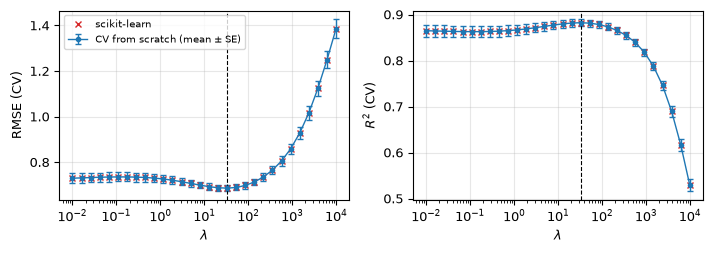

In [24]:
def plota_perfil(eixos, x, perfil, x_otimo, rotulo_x, log=False, referencia=None):
    for ax, met in zip(eixos, ['RMSE', 'R2']):
        ax.errorbar(x, perfil[met], yerr=perfil[f'EP {met}'], fmt='o-', ms=3, lw=1, capsize=2,
                    label='CV from scratch (mean ± SE)')
        if referencia is not None and met in referencia:
            ax.plot(x, referencia[met], 'x', color='tab:red', ms=4, label='scikit-learn')
        ax.axvline(x_otimo, color='k', ls='--', lw=0.8)
        ax.set_xlabel(rotulo_x)
        ax.set_ylabel('RMSE (CV)' if met == 'RMSE' else '$R^2$ (CV)')
        if log:
            ax.set_xscale('log')
    eixos[0].legend(fontsize=7)


fig, eixos = plt.subplots(1, 2, figsize=(7.2, 2.6))
plota_perfil(eixos, grade_lam, perfil_ridge, lam_otimo, '$\\lambda$', log=True,
             referencia={'RMSE': perfil_ridge_sk, 'R2': busca_sk.cv_results_['mean_test_r2']})
fig.tight_layout()
salva_figura(fig, 'perfil_cv_ridge.png')
plt.show()

O perfil tem a forma esperada: para $\lambda$ pequeno o ridge coincide com o OLS; o RMSE cai até um mínimo
e volta a subir quando a penalidade encolhe demais os coeficientes (viés). O ganho em relação ao OLS existe
mas é modesto, porque com 951 observações e 228 preditores o OLS já não está muito superajustado. O caminho
dos coeficientes mostra o encolhimento.

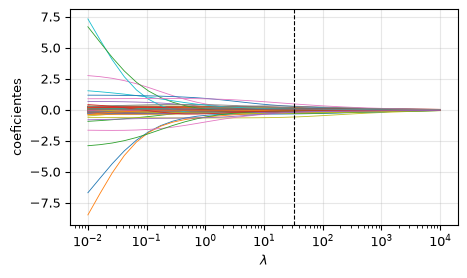

In [25]:
caminho = np.array([RegressaoRidge(lam).fit(Z_treino, y_treino).coef_ for lam in grade_lam])
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.plot(grade_lam, caminho, lw=0.6)
ax.axvline(lam_otimo, color='k', ls='--', lw=0.8)
ax.set_xscale('log')
ax.set_xlabel('$\\lambda$')
ax.set_ylabel('coeficientes')
plt.show()

In [26]:
ridge = RegressaoRidge(lam_otimo).fit(Z_treino, y_treino)
pred_ridge = ridge.predict(Z_teste)
pred_ridge_sk = busca_sk.predict(X_teste)
print(f'Ridge do zero (lambda={lam_otimo:.3f}): RMSE teste = {rmse(y_teste, pred_ridge):.4f}   R2 teste = {r2(y_teste, pred_ridge):.4f}')
print(f'Ridge sklearn                 : RMSE teste = {rmse(y_teste, pred_ridge_sk):.4f}   R2 teste = {r2(y_teste, pred_ridge_sk):.4f}')
print(f'CV no lambda ótimo            : RMSE = {perfil_ridge.loc[i_min, "RMSE"]:.4f}   R2 = {perfil_ridge.loc[i_min, "R2"]:.4f}')
print(f'norma dos coeficientes: OLS {np.linalg.norm(ols.coef_):.2f}  ridge {np.linalg.norm(ridge.coef_):.2f}')

Ridge do zero (lambda=32.903): RMSE teste = 0.7173   R2 teste = 0.8805
Ridge sklearn                 : RMSE teste = 0.7173   R2 teste = 0.8805
CV no lambda ótimo            : RMSE = 0.6862   R2 = 0.8822
norma dos coeficientes: OLS 151.94  ridge 1.47


# QUESTÃO 3: REGRESSÃO POR MÍNIMOS QUADRADOS PARCIAIS (PLS)

Escolhemos o PLS em vez do PCR porque o PLS constrói as componentes maximizando a **covariância** com o
desfecho, enquanto o PCR as escolhe só pela variância dos preditores, sem olhar para $y$. Com preditores
colineares e muitas direções de variância irrelevantes para a solubilidade (como os *fingerprints* raros), o
PLS tende a precisar de menos componentes.

Implementamos o algoritmo NIPALS para o PLS1 (um único desfecho). Em cada componente $a$:
$\mathbf{w}_a \propto \mathbf{E}^\top\mathbf{f}$ (normalizado),
$\mathbf{t}_a = \mathbf{E}\mathbf{w}_a$,
$\mathbf{p}_a = \mathbf{E}^\top\mathbf{t}_a/\mathbf{t}_a^\top\mathbf{t}_a$,
$q_a = \mathbf{f}^\top\mathbf{t}_a/\mathbf{t}_a^\top\mathbf{t}_a$, e a deflação
$\mathbf{E}\leftarrow\mathbf{E}-\mathbf{t}_a\mathbf{p}_a^\top$,
$\mathbf{f}\leftarrow\mathbf{f}-q_a\mathbf{t}_a$.
Os coeficientes no espaço original são
$\boldsymbol\beta = \mathbf{W}(\mathbf{P}^\top\mathbf{W})^{-1}\mathbf{q}$.

In [27]:
class PLS1:
    def __init__(self, n_componentes):
        self.n_componentes = n_componentes

    def fit(self, X, y):
        media_x, media_y = X.mean(axis=0), y.mean()
        E, f = X - media_x, y - media_y
        W, P, q = [], [], []
        for _ in range(self.n_componentes):
            w = E.T @ f
            w /= np.linalg.norm(w)
            t = E @ w
            tt = t @ t
            p = E.T @ t / tt
            qa = f @ t / tt
            E = E - np.outer(t, p)
            f = f - qa * t
            W.append(w); P.append(p); q.append(qa)
        W, P, q = np.array(W).T, np.array(P).T, np.array(q)
        self.coef_ = W @ np.linalg.solve(P.T @ W, q)
        self.intercept_ = media_y - media_x @ self.coef_
        return self

    def predict(self, X):
        return self.intercept_ + X @ self.coef_


for a in (1, 5, 20):
    c0 = PLS1(a).fit(Z_treino, y_treino).coef_
    c1 = PLSRegression(n_components=a, scale=False).fit(Z_treino, y_treino).coef_.ravel()
    print(f'{a:2d} componentes: maior diferença entre coeficientes (zero vs sklearn) = {np.max(np.abs(c0 - c1)):.2e}')

 1 componentes: maior diferença entre coeficientes (zero vs sklearn) = 1.39e-17
 5 componentes: maior diferença entre coeficientes (zero vs sklearn) = 1.11e-16
20 componentes: maior diferença entre coeficientes (zero vs sklearn) = 1.67e-15


Número de componentes de 1 a 40, escolhido pelo menor RMSE médio na validação cruzada de 10 dobras (mesmas
partições), usando só o treino. Para referência, o mesmo perfil é calculado com o `PLSRegression`.

In [28]:
grade_comp = np.arange(1, 41)
perfil_pls, perfil_pls_sk = [], []
for a in grade_comp:
    e, q = valida_cruzado(lambda: PLS1(a), dados_dobras)
    perfil_pls.append((a, e.mean(), e.std(ddof=1) / np.sqrt(K), q.mean(), q.std(ddof=1) / np.sqrt(K)))
    e_sk, _ = valida_cruzado(lambda: PLSRegression(n_components=a, scale=False), dados_dobras)
    perfil_pls_sk.append(e_sk.mean())
perfil_pls = pd.DataFrame(perfil_pls, columns=['componentes', 'RMSE', 'EP RMSE', 'R2', 'EP R2'])

i_pls = perfil_pls['RMSE'].idxmin()
comp_otimo = int(perfil_pls.loc[i_pls, 'componentes'])
comp_1ep = int(perfil_pls.loc[perfil_pls['RMSE'] <= perfil_pls.loc[i_pls, 'RMSE'] + perfil_pls.loc[i_pls, 'EP RMSE'],
                              'componentes'].min())
print(perfil_pls.iloc[::3].round(4).to_string(index=False))
print(f'\ncomponentes ótimo (menor RMSE) = {comp_otimo}   regra de 1 EP: {comp_1ep}')
print(f'maior diferença entre perfis (zero vs sklearn): {np.max(np.abs(perfil_pls["RMSE"] - perfil_pls_sk)):.2e}')

 componentes   RMSE  EP RMSE     R2  EP R2
           1 1.2895   0.0355 0.5856 0.0274
           4 0.8733   0.0172 0.8091 0.0123
           7 0.7589   0.0169 0.8559 0.0096
          10 0.7255   0.0137 0.8674 0.0101
          13 0.7159   0.0135 0.8715 0.0088
          16 0.7076   0.0144 0.8747 0.0085
          19 0.7060   0.0159 0.8750 0.0090
          22 0.7118   0.0153 0.8731 0.0088
          25 0.7191   0.0160 0.8704 0.0090
          28 0.7280   0.0164 0.8668 0.0099
          31 0.7317   0.0150 0.8647 0.0109
          34 0.7360   0.0152 0.8632 0.0110
          37 0.7372   0.0159 0.8625 0.0115
          40 0.7397   0.0168 0.8613 0.0120

componentes ótimo (menor RMSE) = 19   regra de 1 EP: 11
maior diferença entre perfis (zero vs sklearn): 5.55e-16


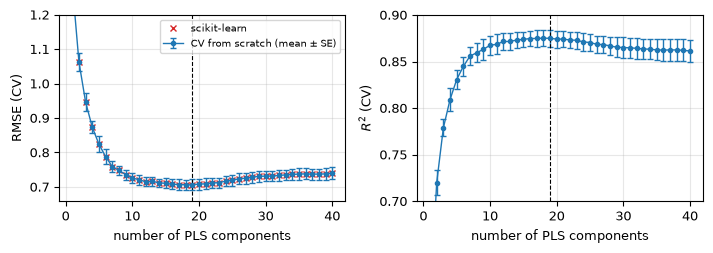

In [29]:
fig, eixos = plt.subplots(1, 2, figsize=(7.2, 2.6))
plota_perfil(eixos, grade_comp, perfil_pls, comp_otimo, 'number of PLS components',
             referencia={'RMSE': np.array(perfil_pls_sk)})
eixos[0].set_ylim(top=1.2)
eixos[1].set_ylim(bottom=0.7)
fig.tight_layout()
salva_figura(fig, 'perfil_cv_pls.png')
plt.show()

In [30]:
pls = PLS1(comp_otimo).fit(Z_treino, y_treino)
pred_pls = pls.predict(Z_teste)
print(f'PLS ({comp_otimo} componentes): RMSE teste = {rmse(y_teste, pred_pls):.4f}   R2 teste = {r2(y_teste, pred_pls):.4f}')
print(f'CV no ótimo           : RMSE = {perfil_pls.loc[i_pls, "RMSE"]:.4f}   R2 = {perfil_pls.loc[i_pls, "R2"]:.4f}')

PLS (19 componentes): RMSE teste = 0.7337   R2 teste = 0.8750
CV no ótimo           : RMSE = 0.7060   R2 = 0.8750


O RMSE cai rapidamente nas primeiras componentes e se estabiliza por volta de 15 a 20: com menos de um décimo
das 228 dimensões o PLS já iguala o OLS, o que confirma que a informação relevante para a solubilidade está
concentrada em poucas direções latentes. A partir do ótimo, mais componentes aproximam o PLS do OLS e o RMSE
volta a subir lentamente. A regra de um erro padrão escolheria um modelo bem menor, com desempenho
praticamente igual.

# QUESTÃO 4: REDE NEURAL PARA REGRESSÃO

Usamos um perceptron multicamadas com uma camada oculta (`MLPRegressor` do scikit-learn), ativação
tangente hiperbólica, saída linear e treino por L-BFGS, que é o otimizador mais adequado para conjuntos
pequenos. O desfecho é padronizado durante o treino (e revertido na predição) para que a escala da saída
seja compatível com a inicialização dos pesos. A rede tem $H(D+1)+H+1$ parâmetros, o que já passa de mil
com $H=5$; por isso a regularização L2 dos pesos (`alpha`, *weight decay*) é essencial.

O número de neurônios ocultos $H$ e `alpha` são escolhidos por validação cruzada de 10 dobras com as mesmas
partições, usando apenas o treino.

In [31]:
def fabrica_mlp(h, alpha, semente=0):
    rede = MLPRegressor(hidden_layer_sizes=(h,), activation='tanh', solver='lbfgs', alpha=alpha,
                        max_iter=2000, random_state=semente)
    return TransformedTargetRegressor(regressor=rede, transformer=StandardScaler())


grade_h = [5, 10, 20, 40]
grade_alpha = [1, 3, 10, 30, 100]
perfil_mlp = []
for h in grade_h:
    for alpha in grade_alpha:
        e, q = valida_cruzado(lambda: fabrica_mlp(h, alpha), dados_dobras)
        perfil_mlp.append((h, alpha, e.mean(), e.std(ddof=1) / np.sqrt(K), q.mean()))
perfil_mlp = pd.DataFrame(perfil_mlp, columns=['H', 'alpha', 'RMSE', 'EP RMSE', 'R2'])
melhor_mlp = perfil_mlp.loc[perfil_mlp['RMSE'].idxmin()]
h_otimo, alpha_otimo = int(melhor_mlp['H']), float(melhor_mlp['alpha'])
print(perfil_mlp.pivot(index='H', columns='alpha', values='RMSE').round(4))
print(f'\nmelhor configuração: H = {h_otimo}, alpha = {alpha_otimo:g}  '
      f'(RMSE CV = {melhor_mlp["RMSE"]:.4f}, R2 CV = {melhor_mlp["R2"]:.4f})')

alpha     1       3       10      30      100
H                                            
5      0.8426  0.7627  0.6634  0.6525  0.7605
10     0.7430  0.7054  0.6433  0.6367  0.7375
20     0.7374  0.6872  0.6330  0.6387  0.7338
40     0.7143  0.6820  0.6313  0.6370  0.7359

melhor configuração: H = 40, alpha = 10  (RMSE CV = 0.6313, R2 CV = 0.9004)


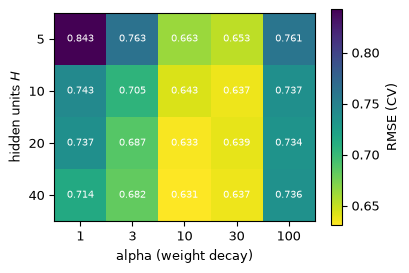

In [32]:
fig, ax = plt.subplots(figsize=(4.2, 2.8))
tabela_mlp = perfil_mlp.pivot(index='H', columns='alpha', values='RMSE')
im = ax.imshow(tabela_mlp.to_numpy(), cmap='viridis_r')
ax.set_xticks(range(len(grade_alpha))); ax.set_xticklabels(grade_alpha)
ax.set_yticks(range(len(grade_h))); ax.set_yticklabels(grade_h)
ax.set_xlabel('alpha (weight decay)'); ax.set_ylabel('hidden units $H$')
ax.grid(False)
for i in range(len(grade_h)):
    for j in range(len(grade_alpha)):
        ax.text(j, i, f'{tabela_mlp.iat[i, j]:.3f}', ha='center', va='center', fontsize=7, color='w')
fig.colorbar(im, ax=ax, label='RMSE (CV)')
salva_figura(fig, 'grade_cv_mlp.png')
plt.show()

A inicialização aleatória dos pesos faz o resultado da rede variar com a semente. Treinamos o modelo final
com a configuração escolhida e semente 0, e para medir essa variabilidade repetimos o treino com outras 9
sementes.

In [33]:
mlp = fabrica_mlp(h_otimo, alpha_otimo).fit(Z_treino, y_treino)
pred_mlp = mlp.predict(Z_teste)
print(f'MLP (H={h_otimo}, alpha={alpha_otimo:g}): RMSE teste = {rmse(y_teste, pred_mlp):.4f}   R2 teste = {r2(y_teste, pred_mlp):.4f}')

rmse_sementes = [rmse(y_teste, fabrica_mlp(h_otimo, alpha_otimo, s).fit(Z_treino, y_treino).predict(Z_teste))
                 for s in range(10)]
print(f'RMSE de teste em 10 sementes: média {np.mean(rmse_sementes):.4f}, desvio {np.std(rmse_sementes, ddof=1):.4f}, '
      f'faixa [{np.min(rmse_sementes):.4f}, {np.max(rmse_sementes):.4f}]')

MLP (H=40, alpha=10): RMSE teste = 0.6202   R2 teste = 0.9107


RMSE de teste em 10 sementes: média 0.6314, desvio 0.0101, faixa [0.6144, 0.6448]


# COMPARAÇÃO ENTRE OS MODELOS

## Desempenho no teste

In [34]:
predicoes = {'OLS': pred_ols, 'Ridge': pred_ridge, 'PLS': pred_pls, 'MLP': pred_mlp}
cv_modelos = {'OLS': (cv_rmse_ols.mean(), cv_r2_ols.mean()),
              'Ridge': (perfil_ridge.loc[i_min, 'RMSE'], perfil_ridge.loc[i_min, 'R2']),
              'PLS': (perfil_pls.loc[i_pls, 'RMSE'], perfil_pls.loc[i_pls, 'R2']),
              'MLP': (melhor_mlp['RMSE'], melhor_mlp['R2'])}
hiper = {'OLS': '---', 'Ridge': f'lambda = {lam_otimo:.2f}', 'PLS': f'{comp_otimo} componentes',
         'MLP': f'H = {h_otimo}, alpha = {alpha_otimo:g}'}

# intervalo de confiança de 95% por bootstrap das observações de teste
rng = np.random.default_rng(SEMENTE)
amostras = rng.integers(0, len(y_teste), size=(2000, len(y_teste)))
ic = {m: np.percentile([rmse(y_teste[a], p[a]) for a in amostras], [2.5, 97.5]) for m, p in predicoes.items()}

resultados = pd.DataFrame({
    'hiperparâmetro': hiper,
    'RMSE CV': {m: v[0] for m, v in cv_modelos.items()},
    'R2 CV': {m: v[1] for m, v in cv_modelos.items()},
    'RMSE teste': {m: rmse(y_teste, p) for m, p in predicoes.items()},
    'IC95% RMSE': {m: f'[{ic[m][0]:.3f}, {ic[m][1]:.3f}]' for m in predicoes},
    'R2 teste': {m: r2(y_teste, p) for m, p in predicoes.items()},
})
print(resultados.round(4).to_string())

           hiperparâmetro  RMSE CV   R2 CV  RMSE teste      IC95% RMSE  R2 teste
OLS                   ---   0.7279  0.8654      0.7430  [0.668, 0.822]    0.8718
Ridge      lambda = 32.90   0.6862  0.8822      0.7173  [0.646, 0.791]    0.8805
PLS        19 componentes   0.7060  0.8750      0.7337  [0.663, 0.806]    0.8750
MLP    H = 40, alpha = 10   0.6313  0.9004      0.6202  [0.549, 0.694]    0.9107


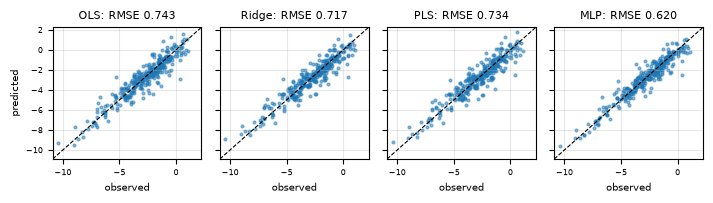

In [35]:
fig, eixos = plt.subplots(1, 4, figsize=(7.2, 2.1), sharex=True, sharey=True)
lim = [min(y_teste.min(), min(p.min() for p in predicoes.values())) - 0.5,
       max(y_teste.max(), max(p.max() for p in predicoes.values())) + 0.5]
for ax, (m, p) in zip(eixos, predicoes.items()):
    ax.scatter(y_teste, p, s=4, alpha=0.5)
    ax.plot(lim, lim, 'k--', lw=0.8)
    ax.set_title(f'{m}: RMSE {rmse(y_teste, p):.3f}', fontsize=8)
    ax.set_xlabel('observed', fontsize=7)
    ax.tick_params(labelsize=6)
eixos[0].set_ylabel('predicted', fontsize=7)
ax.set_xlim(lim); ax.set_ylim(lim)
fig.tight_layout()
salva_figura(fig, 'observado_vs_predito.png')
plt.show()

Onde está a diferença? Dividimos os compostos de teste em faixas de solubilidade e calculamos, em cada uma, o
RMSE e o erro médio (observado menos predito) de cada modelo.

In [36]:
faixas = pd.cut(y_teste, bins=[-12, -6, -4, -2, 0, 2])
por_faixa = pd.DataFrame({'n': pd.Series(y_teste).groupby(faixas, observed=True).size()})
for m, p in predicoes.items():
    erro = pd.Series(y_teste - p)
    por_faixa[f'RMSE {m}'] = erro.groupby(faixas, observed=True).apply(lambda e: np.sqrt(np.mean(e ** 2)))
    por_faixa[f'viés {m}'] = erro.groupby(faixas, observed=True).mean()
print(por_faixa.round(3).to_string())

             n  RMSE OLS  viés OLS  RMSE Ridge  viés Ridge  RMSE PLS  viés PLS  RMSE MLP  viés MLP
(-12, -6]   29     0.751    -0.251       0.816      -0.433     0.764    -0.348     0.608    -0.188
(-6, -4]    48     0.719    -0.222       0.736      -0.287     0.727    -0.242     0.627    -0.191
(-4, -2]   114     0.710    -0.030       0.665      -0.056     0.715    -0.026     0.598    -0.070
(-2, 0]    105     0.724     0.100       0.662       0.116     0.691     0.094     0.573     0.076
(0, 2]      20     1.018     0.528       1.022       0.604     0.988     0.530     0.912     0.588


## Há diferença estatística entre os modelos?

Diferenças de poucos centésimos no RMSE de um único conjunto de teste podem ser ruído. Usamos duas
abordagens complementares:

1. **Validação cruzada repetida** (5 repetições de 10 dobras, as mesmas partições para todos os modelos,
   hiperparâmetros fixos nos valores escolhidos acima). Para cada par de modelos, as diferenças de RMSE por
   dobra são comparadas com o teste *t* corrigido de Nadeau e Bengio, que infla a variância para levar em
   conta a sobreposição entre os conjuntos de treino das dobras (o teste *t* pareado comum é otimista
   nesse caso):
   $t = \bar d \,/\, \sqrt{\left(\tfrac{1}{kr} + \tfrac{n_{va}}{n_{tr}}\right) s_d^2}$, com $kr-1$ graus de liberdade.
2. **Conjunto de teste**: teste de postos sinalizados de Wilcoxon sobre os erros quadráticos pareados por
   composto.

Em ambos os casos os *p*-valores dos 6 pares são ajustados pelo método de Holm para comparações múltiplas.

In [37]:
R_REP = 5
particoes_rep = [p for r in range(R_REP) for p in particiona_kfold(len(y_treino), K, SEMENTE + 1 + r)]
dados_rep = prepara_dobras(X_treino, y_treino, particoes_rep)

fabricas = {'OLS': OLS, 'Ridge': lambda: RegressaoRidge(lam_otimo), 'PLS': lambda: PLS1(comp_otimo),
            'MLP': lambda: fabrica_mlp(h_otimo, alpha_otimo)}
rmse_rep = pd.DataFrame({m: valida_cruzado(f, dados_rep)[0] for m, f in fabricas.items()})
print(rmse_rep.describe().loc[['mean', 'std', 'min', 'max']].round(4))

         OLS   Ridge     PLS     MLP
mean  0.7296  0.6909  0.7152  0.6348
std   0.0833  0.0673  0.0650  0.0653
min   0.5796  0.5813  0.6156  0.5103
max   1.0020  0.9108  0.9421  0.8643


In [38]:
def holm(p):
    p = np.asarray(p); ordem = np.argsort(p); m = len(p)
    ajust = np.empty(m)
    ajust[ordem] = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[ordem]))
    return ajust


def t_corrigido(d, n_tr, n_va):
    """Teste t de reamostragem corrigido (Nadeau & Bengio, 2003), bicaudal."""
    J = len(d)
    t = d.mean() / np.sqrt((1 / J + n_va / n_tr) * d.var(ddof=1))
    return t, 2 * stats.t.sf(abs(t), df=J - 1)


n_va = len(y_treino) / K
n_tr = len(y_treino) - n_va
modelos = list(predicoes)
pares = [(a, b) for i, a in enumerate(modelos) for b in modelos[i + 1:]]
linhas = []
for a, b in pares:
    d_cv = rmse_rep[a].to_numpy() - rmse_rep[b].to_numpy()
    t, p_cv = t_corrigido(d_cv, n_tr, n_va)
    e_a, e_b = (y_teste - predicoes[a]) ** 2, (y_teste - predicoes[b]) ** 2
    p_te = stats.wilcoxon(e_a, e_b).pvalue
    linhas.append((f'{a} - {b}', d_cv.mean(), t, p_cv, rmse(y_teste, predicoes[a]) - rmse(y_teste, predicoes[b]), p_te))
testes = pd.DataFrame(linhas, columns=['par', 'dif. RMSE CV', 't corrigido', 'p CV', 'dif. RMSE teste', 'p teste'])
testes['p CV (Holm)'] = holm(testes['p CV'])
testes['p teste (Holm)'] = holm(testes['p teste'])
print(testes.round(4).to_string(index=False))

        par  dif. RMSE CV  t corrigido   p CV  dif. RMSE teste  p teste  p CV (Holm)  p teste (Holm)
OLS - Ridge        0.0387       2.1047 0.0405           0.0256   0.4361       0.0809          0.8721
  OLS - PLS        0.0143       0.8739 0.3864           0.0093   0.5384       0.3864          0.8721
  OLS - MLP        0.0947       4.8262 0.0000           0.1228   0.0000       0.0001          0.0000
Ridge - PLS       -0.0243      -3.1540 0.0028          -0.0164   0.0684       0.0083          0.2052
Ridge - MLP        0.0561       4.1363 0.0001           0.0972   0.0000       0.0006          0.0000
  PLS - MLP        0.0804       5.6960 0.0000           0.1136   0.0000       0.0000          0.0000


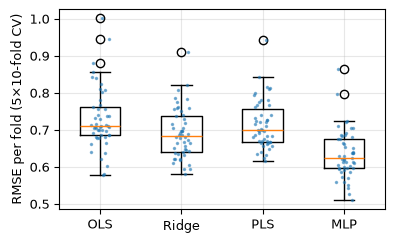

In [39]:
fig, ax = plt.subplots(figsize=(4.2, 2.6))
ax.boxplot([rmse_rep[m] for m in modelos], tick_labels=modelos, widths=0.5)
for k, m in enumerate(modelos, start=1):
    ax.plot(np.full(len(rmse_rep), k) + np.random.default_rng(k).uniform(-0.12, 0.12, len(rmse_rep)),
            rmse_rep[m], '.', ms=3, alpha=0.5, color='tab:blue')
ax.set_ylabel(f'RMSE per fold ({R_REP}×{K}-fold CV)')
salva_figura(fig, 'cv_repetida_modelos.png')
plt.show()

**Leitura.** Os três modelos lineares (OLS, ridge e PLS) têm desempenho praticamente igual: as diferenças
entre eles são pequenas frente à variação entre dobras. A rede neural tem o menor RMSE tanto na validação
cruzada quanto no teste, e as comparações dela contra cada modelo linear são as que se destacam nos testes.
O fato de um modelo não linear superar os lineares indica que a relação entre os preditores e a solubilidade
não é inteiramente linear, mesmo após a transformação que linearizou as relações individuais: parte do sinal
está em curvaturas e em **interações** entre preditores (por exemplo, o efeito de um grupo funcional
dependendo do tamanho da molécula), que um modelo aditivo e linear não consegue representar.

# EXPORTAÇÃO DAS TABELAS PARA O ARTIGO

As tabelas do artigo não são digitadas à mão: as células abaixo escrevem os fragmentos LaTeX em
`paper/tabelas/`, que o `paper/main.tex` inclui com `\input`. As figuras já foram salvas em `figuras/` ao
longo do notebook.

In [40]:
def escreve(nome_arquivo, linhas):
    r"""Grava um fragmento de tabela LaTeX.

    A última linha sai SEM o '\\' final: o \input do LaTeX expande para '\@@input <arquivo>\relax', e esse
    \relax depois de um '\\' abre uma célula nova, fazendo o \bottomrule seguinte virar 'Misplaced \noalign'.
    Quem fecha a última linha é o '\\' escrito no main.tex logo após o \input.
    """
    corpo = '\n'.join(linhas).rstrip()
    if corpo.endswith('\\\\'):
        corpo = corpo[:-2].rstrip()
    with open(os.path.join(DIR_TAB, nome_arquivo), 'w', encoding='utf-8') as arq:
        arq.write(corpo + '\n')
    print('  escrito', os.path.join(DIR_TAB, nome_arquivo))


def tex(nome):
    return nome.replace('_', r'\_')


# assimetria: as contínuas e as contagens mais e menos afetadas
sel = ['MolWeight', 'SurfaceArea1', 'HydrophilicFactor', 'NumCarbon', 'NumRotBonds', 'NumOxygen',
       'NumChlorine', 'NumSulfer']
escreve('assimetria.tex', [
    f"{tex(c)} & {tabela_assim.loc[c, 'lambda']:.2f} & {tabela_assim.loc[c, 'assim. antes']:.2f} & "
    f"{tabela_assim.loc[c, 'assim. depois (treino)']:.2f} & {100 * tabela_assim.loc[c, 'fração de zeros']:.0f}\\% \\\\"
    for c in sel])

escreve('ols.tex', [
    f"Test set, from scratch & {rmse(y_teste, pred_ols):.4f} & {r2(y_teste, pred_ols):.4f} \\\\",
    f"Test set, scikit-learn & {rmse(y_teste, pred_ols_sk):.4f} & {r2(y_teste, pred_ols_sk):.4f} \\\\",
    r"\midrule",
    f"10-fold CV, from scratch & {cv_rmse_ols.mean():.4f} $\\pm$ {cv_rmse_ols.std(ddof=1):.3f} & "
    f"{cv_r2_ols.mean():.4f} $\\pm$ {cv_r2_ols.std(ddof=1):.3f} \\\\",
    f"10-fold CV, scikit-learn & {cv_rmse_ols_sk.mean():.4f} $\\pm$ {cv_rmse_ols_sk.std(ddof=1):.3f} & "
    f"{cv_r2_ols_sk.mean():.4f} $\\pm$ {cv_r2_ols_sk.std(ddof=1):.3f} \\\\",
    f"5-fold CV, from scratch & {cv5_rmse_ols.mean():.4f} $\\pm$ {cv5_rmse_ols.std(ddof=1):.3f} & "
    f"{cv5_r2_ols.mean():.4f} $\\pm$ {cv5_r2_ols.std(ddof=1):.3f} \\\\",
])

rotulos_hiper = {'OLS': '---', 'Ridge': f'$\\lambda = {lam_otimo:.1f}$', 'PLS': f'$A = {comp_otimo}$',
                 'MLP': f'$H = {h_otimo}$, $\\alpha = {alpha_otimo:g}$'}
escreve('resultados.tex', [
    f"{m} & {rotulos_hiper[m]} & {resultados.loc[m, 'RMSE CV']:.3f} & {resultados.loc[m, 'R2 CV']:.3f} & "
    f"{resultados.loc[m, 'RMSE teste']:.3f} & {ic[m][0]:.3f}--{ic[m][1]:.3f} & {resultados.loc[m, 'R2 teste']:.3f} \\\\"
    for m in modelos])


def fmt_p(p):
    return '$<0.001$' if p < 0.001 else f'{p:.3f}'


escreve('testes.tex', [
    f"{r['par'].replace(' - ', ' vs. ')} & {r['dif. RMSE CV']:+.3f} & {fmt_p(r['p CV (Holm)'])} & "
    f"{r['dif. RMSE teste']:+.3f} & {fmt_p(r['p teste (Holm)'])} \\\\"
    for _, r in testes.iterrows()])

  escrito paper/tabelas/assimetria.tex
  escrito paper/tabelas/ols.tex
  escrito paper/tabelas/resultados.tex
  escrito paper/tabelas/testes.tex


Resumo numérico usado no texto do artigo.

In [41]:
print(f'N treino = {len(y_treino)}, N teste = {len(y_teste)}, D = {X_treino.shape[1]}')
print(f'|assimetria| mediana dos 20 não binários: antes {tabela_assim["assim. antes"].abs().median():.2f}, '
      f'depois {tabela_assim["assim. depois (treino)"].abs().median():.2f}')
print(f'pares |r| > 0.9: {np.sum(np.abs(r_pares) > 0.9)}  |r| mediano: {np.median(np.abs(r_pares)):.3f}')
print(f'cond(Z^T Z) = {autovalores_R[0] / autovalores_R[-1]:.2e}')
print(f'lambda* = {lam_otimo:.3f} (1-EP: {lam_1ep:.3f}),  A* = {comp_otimo} (1-EP: {comp_1ep}),  '
      f'MLP H = {h_otimo}, alpha = {alpha_otimo:g}')
print(resultados.round(4).to_string())

N treino = 951, N teste = 316, D = 228
|assimetria| mediana dos 20 não binários: antes 1.36, depois 0.06
pares |r| > 0.9: 47  |r| mediano: 0.091
cond(Z^T Z) = 9.82e+08
lambda* = 32.903 (1-EP: 85.317),  A* = 19 (1-EP: 11),  MLP H = 40, alpha = 10
           hiperparâmetro  RMSE CV   R2 CV  RMSE teste      IC95% RMSE  R2 teste
OLS                   ---   0.7279  0.8654      0.7430  [0.668, 0.822]    0.8718
Ridge      lambda = 32.90   0.6862  0.8822      0.7173  [0.646, 0.791]    0.8805
PLS        19 componentes   0.7060  0.8750      0.7337  [0.663, 0.806]    0.8750
MLP    H = 40, alpha = 10   0.6313  0.9004      0.6202  [0.549, 0.694]    0.9107
